Supplementary Figure: branch-specific stress tests

In [1]:
# ============================================================
# Supplementary Simulation — Branch-specific stress tests
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso
import isovita_simulation as isim


SIGNAL_STRENGTHS = np.array(
    [
        0.05,
        0.10,
        0.20,
        0.40,
        0.80,
    ],
    dtype=float,
)

N_SAMPLES = 180
K = 4

GENES_PER_STRENGTH = 2

# 5 strengths × 2 genes = 10 alternative genes.
N_ALT = (
    len(SIGNAL_STRENGTHS)
    * GENES_PER_STRENGTH
)

N_NULL = N_ALT

N_REPLICATES = 15

NOISE_SD = 0.30
NOISE_CORR = 0.10
BASELINE_SD = 0.22

ALPHA_FDR = 0.05

BASE_SEED = 20260927


# ============================================================
# Discrete geometry
# ============================================================

STEP_LOCATIONS = [
    15.0,
    30.0,
    45.0,
    65.0,
]


# ============================================================
# Continuous geometry
# ============================================================

CONTINUOUS_SHAPES = [
    "linear",
    "sigmoid",
    "u_shape",
    "sinusoid",
]


# ============================================================
# Localized geometry
#
# Default windows:
#   0-10, 10-20, 20-40, 40-85
# ============================================================

LOCALIZED_CASES = {
    "Early\n0–10": {
        "center": 5.0,
        "width": 3.0,
        "acceptable_windows": (
            "0-10",
        ),
    },

    "Middle\n10–20": {
        "center": 15.0,
        "width": 3.0,
        "acceptable_windows": (
            "10-20",
        ),
    },

    "Boundary\n20": {
        "center": 20.0,
        "width": 4.0,
        "acceptable_windows": (
            "10-20",
            "20-40",
        ),
    },

    "Middle\n20–40": {
        "center": 30.0,
        "width": 5.0,
        "acceptable_windows": (
            "20-40",
        ),
    },

    "Boundary\n40": {
        "center": 40.0,
        "width": 5.0,
        "acceptable_windows": (
            "20-40",
            "40-85",
        ),
    },
}


# Branch-specific permutation counts.
#
# Discrete / continuous:
#   20 gene hypotheses
#
# Localized:
#   20 genes × 4 windows = 80 hypotheses
#
# 1/(2000+1) ~= 0.00050
# 0.05/80 = 0.000625
BRANCH_PERMUTATIONS = {
    "discrete": 1000,
    "continuous": 1000,
    "localized": 2000,
}

In [2]:
# ============================================================
# Common helpers
# ============================================================

REFERENCE_LOADINGS = np.array(
    [
        1.00,
        0.82,
        -0.92,
        -0.75,
    ],
    dtype=float,
)


def make_loadings(
    rng,
):

    loading = (
        REFERENCE_LOADINGS
        + rng.normal(
            0.0,
            0.04,
            size=K,
        )
    )

    loading -= (
        loading.mean()
    )

    loading /= np.max(
        np.abs(loading)
    )

    return tuple(
        loading.tolist()
    )


def make_gene_baselines(
    rng,
):

    return tuple(
        rng.normal(
            0.0,
            BASELINE_SD,
            size=K,
        ).tolist()
    )


def continuous_component(
    shape,
    loadings,
    amplitude,
):

    if shape == "linear":

        return isim.TemporalComponent(
            kind="linear",
            loadings=loadings,
            amplitude=float(amplitude),
        )

    if shape == "sigmoid":

        return isim.TemporalComponent(
            kind="sigmoid",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "center": 42.0,
                "scale": 16.0,
            },
        )

    if shape == "u_shape":

        return isim.TemporalComponent(
            kind="u_shape",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "center": 42.5,
                "scale": 42.5,
            },
        )

    if shape == "sinusoid":

        return isim.TemporalComponent(
            kind="sinusoid",
            loadings=loadings,
            amplitude=float(amplitude),
            params={
                "cycles": 1.0,
                "phase": 0.0,
            },
        )

    raise ValueError(
        shape
    )

In [3]:
# ============================================================
# Build one branch-specific simulated dataset
# ============================================================

def make_branch_stress_scenarios(
    branch,
    geometry_label,
    replicate,
):
    """
    One dataset contains:

      10 null genes
      10 alternative genes
        = 2 genes at each of 5 signal strengths

    Only one branch is tested in each stress experiment.
    """

    seed = (
        BASE_SEED
        + 100_000 * replicate
        + sum(
            ord(x)
            for x
            in (
                branch
                + str(
                    geometry_label
                )
            )
        )
    )

    rng = np.random.default_rng(
        seed
    )

    scenarios = []
    truth_rows = []

    # --------------------------------------------------------
    # Null genes
    # --------------------------------------------------------

    for i in range(
        N_NULL
    ):

        gene_id = (
            f"R{replicate:03d}_"
            f"{branch}_NULL_"
            f"{i + 1:03d}"
        )

        scenarios.append(
            isim.IsoformScenario(
                gene_id=gene_id,
                label="Age-null",
                baselines=(
                    make_gene_baselines(
                        rng
                    )
                ),
                components=(),
                noise_sd=NOISE_SD,
                noise_corr=NOISE_CORR,
            )
        )

        truth_rows.append({
            "gene_id": gene_id,
            "truth_type": "null",
            "signal_strength": 0.0,
            "geometry": geometry_label,
        })

    # --------------------------------------------------------
    # Alternative genes
    # --------------------------------------------------------

    for strength in (
        SIGNAL_STRENGTHS
    ):

        for gene_index in range(
            GENES_PER_STRENGTH
        ):

            gene_id = (
                f"R{replicate:03d}_"
                f"{branch}_"
                f"{str(geometry_label).replace(' ', '_')}_"
                f"{strength:g}_"
                f"G{gene_index + 1}"
            )

            loadings = (
                make_loadings(
                    rng
                )
            )

            if branch == "discrete":

                component = (
                    isim.TemporalComponent(
                        kind="step",
                        loadings=loadings,
                        amplitude=float(
                            strength
                        ),
                        params={
                            "change_age":
                                float(
                                    geometry_label
                                )
                        },
                    )
                )

                extra_truth = {
                    "true_change_age":
                        float(
                            geometry_label
                        )
                }

            elif branch == "continuous":

                component = (
                    continuous_component(
                        geometry_label,
                        loadings,
                        strength,
                    )
                )

                extra_truth = {}

            elif branch == "localized":

                case = (
                    LOCALIZED_CASES[
                        geometry_label
                    ]
                )

                component = (
                    isim.TemporalComponent(
                        kind="localized",
                        loadings=loadings,
                        amplitude=float(
                            strength
                        ),
                        params={
                            "center":
                                case[
                                    "center"
                                ],

                            "width":
                                case[
                                    "width"
                                ],
                        },
                    )
                )

                extra_truth = {
                    "acceptable_windows":
                        "|".join(
                            case[
                                "acceptable_windows"
                            ]
                        )
                }

            else:
                raise ValueError(
                    branch
                )

            scenarios.append(
                isim.IsoformScenario(
                    gene_id=gene_id,
                    label=str(
                        geometry_label
                    ),
                    baselines=(
                        make_gene_baselines(
                            rng
                        )
                    ),
                    components=(
                        component,
                    ),
                    noise_sd=NOISE_SD,
                    noise_corr=NOISE_CORR,
                )
            )

            row = {
                "gene_id":
                    gene_id,

                "truth_type":
                    branch,

                "signal_strength":
                    float(strength),

                "geometry":
                    geometry_label,
            }

            row.update(
                extra_truth
            )

            truth_rows.append(
                row
            )

    return (
        tuple(
            scenarios
        ),
        pd.DataFrame(
            truth_rows
        ),
    )

In [4]:
# ============================================================
# Run one branch-specific stress condition
# ============================================================

def run_branch_stress_condition(
    branch,
    geometry_label,
    replicate,
):

    (
        scenarios,
        truth,
    ) = make_branch_stress_scenarios(
        branch,
        geometry_label,
        replicate,
    )

    sim_data = (
        isim.simulate_isovita_dataset(
            scenarios,
            n_samples=N_SAMPLES,
            age_min=0,
            age_max=85,
            age_design="uniform",
            seed=(
                BASE_SEED
                + 200_000
                * replicate
                + sum(
                    ord(x)
                    for x
                    in str(
                        geometry_label
                    )
                )
            ),
        )
    )

    sample_cols = (
        sim_data.metadata
        .index
        .tolist()
    )

    (
        balance_summary,
        _,
        balance_feature_matrix,
    ) = iso.build_one_feature_per_gene(
        expression_df=(
            sim_data.expression
        ),
        global_metrics=(
            sim_data.global_metrics
        ),
        sample_cols=sample_cols,
        metadata=sim_data.metadata,
        config=iso.BalanceConfig(),
    )

    branch_results = (
        iso.run_selection_aware_temporal_tests(
            expression_df=(
                sim_data.expression
            ),
            global_metrics=(
                sim_data.global_metrics
            ),
            sample_cols=sample_cols,
            metadata=sim_data.metadata,
            branches=(
                branch,
            ),
            observed_feature_matrix=(
                balance_feature_matrix
            ),
            balance_config=(
                iso.BalanceConfig()
            ),
            discrete_config=(
                iso.DiscreteConfig(
                    alpha_fdr=ALPHA_FDR
                )
            ),
            feature_config=(
                iso.FeatureTestConfig(
                    alpha_fdr=ALPHA_FDR
                )
            ),
            windows=(
                iso.WindowConfig()
            ),
            inference_config=(
                iso.PermutationInferenceConfig(
                    n_permutations=(
                        BRANCH_PERMUTATIONS[
                            branch
                        ]
                    ),
                    random_seed=(
                        BASE_SEED
                        + 300_000
                        * replicate
                        + sum(
                            ord(x)
                            for x
                            in (
                                branch
                                + str(
                                    geometry_label
                                )
                            )
                        )
                    ),
                )
            ),
        )
    )

    empty = pd.DataFrame()

    gene_summary = (
        iso.summarize_gene_trajectories(
            balance_summary,
            (
                branch_results[
                    "discrete"
                ]
                if branch
                == "discrete"
                else empty
            ),
            (
                branch_results[
                    "continuous"
                ]
                if branch
                == "continuous"
                else empty
            ),
            (
                branch_results[
                    "localized"
                ]
                if branch
                == "localized"
                else empty
            ),
            branches=(
                branch,
            ),
        )
    )

    if branch == "discrete":

        keep = [
            "gene_id",
            "discrete_fdr_significant",
            "discrete_change_age",
        ]

    elif branch == "continuous":

        keep = [
            "gene_id",
            "continuous_fdr_significant",
        ]

    elif branch == "localized":

        keep = [
            "gene_id",
            "localized_fdr_significant",
            "best_window",
            "n_significant_windows",
            "significant_windows",
        ]

    calls = (
        truth.merge(
            gene_summary[
                keep
            ],
            on="gene_id",
            how="left",
            validate="one_to_one",
        )
    )

    calls[
        "replicate"
    ] = replicate

    calls[
        "branch"
    ] = branch

    return calls

In [5]:
# ============================================================
# Run branch-specific stress experiments
# ============================================================

branch_stress_results = []


# ------------------------------------------------------------
# Discrete branch
# ------------------------------------------------------------

for change_age in (
    STEP_LOCATIONS
):

    for replicate in range(
        N_REPLICATES
    ):

        print(
            "Discrete | "
            f"change={change_age} | "
            f"rep {replicate + 1}/"
            f"{N_REPLICATES}",
            flush=True,
        )

        branch_stress_results.append(
            run_branch_stress_condition(
                "discrete",
                change_age,
                replicate,
            )
        )


# ------------------------------------------------------------
# Continuous branch
# ------------------------------------------------------------

for shape in (
    CONTINUOUS_SHAPES
):

    for replicate in range(
        N_REPLICATES
    ):

        print(
            "Continuous | "
            f"{shape} | "
            f"rep {replicate + 1}/"
            f"{N_REPLICATES}",
            flush=True,
        )

        branch_stress_results.append(
            run_branch_stress_condition(
                "continuous",
                shape,
                replicate,
            )
        )


# ------------------------------------------------------------
# Localized branch
# ------------------------------------------------------------

for case_label in (
    LOCALIZED_CASES
):

    for replicate in range(
        N_REPLICATES
    ):

        print(
            "Localized | "
            f"{case_label} | "
            f"rep {replicate + 1}/"
            f"{N_REPLICATES}",
            flush=True,
        )

        branch_stress_results.append(
            run_branch_stress_condition(
                "localized",
                case_label,
                replicate,
            )
        )


branch_stress_calls = (
    pd.concat(
        branch_stress_results,
        ignore_index=True,
    )
)

Discrete | change=15.0 | rep 1/15
Discrete | change=15.0 | rep 2/15
Discrete | change=15.0 | rep 3/15
Discrete | change=15.0 | rep 4/15
Discrete | change=15.0 | rep 5/15
Discrete | change=15.0 | rep 6/15
Discrete | change=15.0 | rep 7/15
Discrete | change=15.0 | rep 8/15
Discrete | change=15.0 | rep 9/15
Discrete | change=15.0 | rep 10/15
Discrete | change=15.0 | rep 11/15
Discrete | change=15.0 | rep 12/15
Discrete | change=15.0 | rep 13/15
Discrete | change=15.0 | rep 14/15
Discrete | change=15.0 | rep 15/15
Discrete | change=30.0 | rep 1/15
Discrete | change=30.0 | rep 2/15
Discrete | change=30.0 | rep 3/15
Discrete | change=30.0 | rep 4/15
Discrete | change=30.0 | rep 5/15
Discrete | change=30.0 | rep 6/15
Discrete | change=30.0 | rep 7/15
Discrete | change=30.0 | rep 8/15
Discrete | change=30.0 | rep 9/15
Discrete | change=30.0 | rep 10/15
Discrete | change=30.0 | rep 11/15
Discrete | change=30.0 | rep 12/15
Discrete | change=30.0 | rep 13/15
Discrete | change=30.0 | rep 14/15
Dis

In [6]:
RESULT_DIR = Path(
    "results/simulation_branch_stress"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

branch_stress_calls.to_csv(
    RESULT_DIR
    / "branch_stress_gene_calls.csv",
    index=False,
)

In [ ]:
# ============================================================
# Reload previously computed simulation results
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULT_DIR = Path(
    "results/simulation_branch_stress"
)

branch_stress_calls = pd.read_csv(
    RESULT_DIR / "branch_stress_gene_calls.csv"
)

In [7]:
# ============================================================
# Derived metrics
# ============================================================

branch_stress_calls[
    "called"
] = False


for branch in (
    "discrete",
    "continuous",
    "localized",
):

    mask = (
        branch_stress_calls[
            "branch"
        ].eq(branch)
    )

    column = (
        f"{branch}_fdr_significant"
    )

    branch_stress_calls.loc[
        mask,
        "called",
    ] = (
        branch_stress_calls.loc[
            mask,
            column,
        ]
        .fillna(False)
        .astype(bool)
    )


# ============================================================
# Discrete changepoint error
# ============================================================

discrete_mask = (
    branch_stress_calls[
        "branch"
    ].eq("discrete")
    & ~branch_stress_calls[
        "truth_type"
    ].eq("null")
)

branch_stress_calls.loc[
    discrete_mask,
    "change_age_error",
] = np.abs(
    branch_stress_calls.loc[
        discrete_mask,
        "discrete_change_age",
    ]
    - branch_stress_calls.loc[
        discrete_mask,
        "true_change_age",
    ]
)


# ============================================================
# Localized window recovery
# ============================================================

localized_mask = (
    branch_stress_calls[
        "branch"
    ].eq("localized")
    & ~branch_stress_calls[
        "truth_type"
    ].eq("null")
)


def acceptable_window_hit(
    row,
):

    acceptable = str(
        row[
            "acceptable_windows"
        ]
    ).split("|")

    return (
        str(
            row[
                "best_window"
            ]
        )
        in acceptable
    )


branch_stress_calls.loc[
    localized_mask,
    "acceptable_best_window",
] = (
    branch_stress_calls.loc[
        localized_mask
    ]
    .apply(
        acceptable_window_hit,
        axis=1,
    )
)

In [8]:
# ============================================================
# Replicate-level summaries
# ============================================================

alternative_calls = (
    branch_stress_calls.loc[
        ~branch_stress_calls[
            "truth_type"
        ].eq("null")
    ]
    .copy()
)


# ------------------------------------------------------------
# Power
# ------------------------------------------------------------

power_by_rep = (
    alternative_calls
    .groupby(
        [
            "branch",
            "geometry",
            "signal_strength",
            "replicate",
        ],
        as_index=False,
    )
    .agg(
        power=(
            "called",
            "mean",
        )
    )
)


# ------------------------------------------------------------
# Discrete location error
# ------------------------------------------------------------

discrete_error_by_rep = (
    alternative_calls.loc[
        alternative_calls[
            "branch"
        ].eq(
            "discrete"
        )
    ]
    .groupby(
        [
            "geometry",
            "signal_strength",
            "replicate",
        ],
        as_index=False,
    )
    .agg(
        median_error=(
            "change_age_error",
            "median",
        )
    )
)


# ------------------------------------------------------------
# Localized best-window recovery
# ------------------------------------------------------------

localized_window_by_rep = (
    alternative_calls.loc[
        alternative_calls[
            "branch"
        ].eq(
            "localized"
        )
    ]
    .groupby(
        [
            "geometry",
            "signal_strength",
            "replicate",
        ],
        as_index=False,
    )
    .agg(
        acceptable_window_rate=(
            "acceptable_best_window",
            "mean",
        ),

        mean_significant_windows=(
            "n_significant_windows",
            "mean",
        ),
    )
)


# ============================================================
# Mean + 95% CI helper
# ============================================================

def aggregate_ci(
    df,
    value,
    group_cols,
):

    rows = []

    for keys, sub in df.groupby(
        group_cols,
        sort=False,
    ):

        if not isinstance(
            keys,
            tuple,
        ):
            keys = (
                keys,
            )

        x = (
            sub[
                value
            ]
            .astype(float)
            .to_numpy()
        )

        mean = float(
            np.mean(x)
        )

        se = (
            np.std(
                x,
                ddof=1,
            )
            / np.sqrt(
                len(x)
            )
        )

        row = dict(
            zip(
                group_cols,
                keys,
            )
        )

        row.update({
            "mean":
                mean,

            "ci_low":
                mean
                - 1.96
                * se,

            "ci_high":
                mean
                + 1.96
                * se,
        })

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )


power_summary = aggregate_ci(
    power_by_rep,
    "power",
    [
        "branch",
        "geometry",
        "signal_strength",
    ],
)


discrete_error_summary = (
    discrete_error_by_rep
    .groupby(
        [
            "geometry",
            "signal_strength",
        ],
        as_index=False,
    )
    .agg(
        median_error=(
            "median_error",
            "median",
        ),

        q25=(
            "median_error",
            lambda x:
                np.quantile(
                    x,
                    0.25,
                ),
        ),

        q75=(
            "median_error",
            lambda x:
                np.quantile(
                    x,
                    0.75,
                ),
        ),
    )
)


localized_window_summary = (
    aggregate_ci(
        localized_window_by_rep,
        "acceptable_window_rate",
        [
            "geometry",
            "signal_strength",
        ],
    )
)


localized_multiplicity_summary = (
    aggregate_ci(
        localized_window_by_rep,
        "mean_significant_windows",
        [
            "geometry",
            "signal_strength",
        ],
    )
)

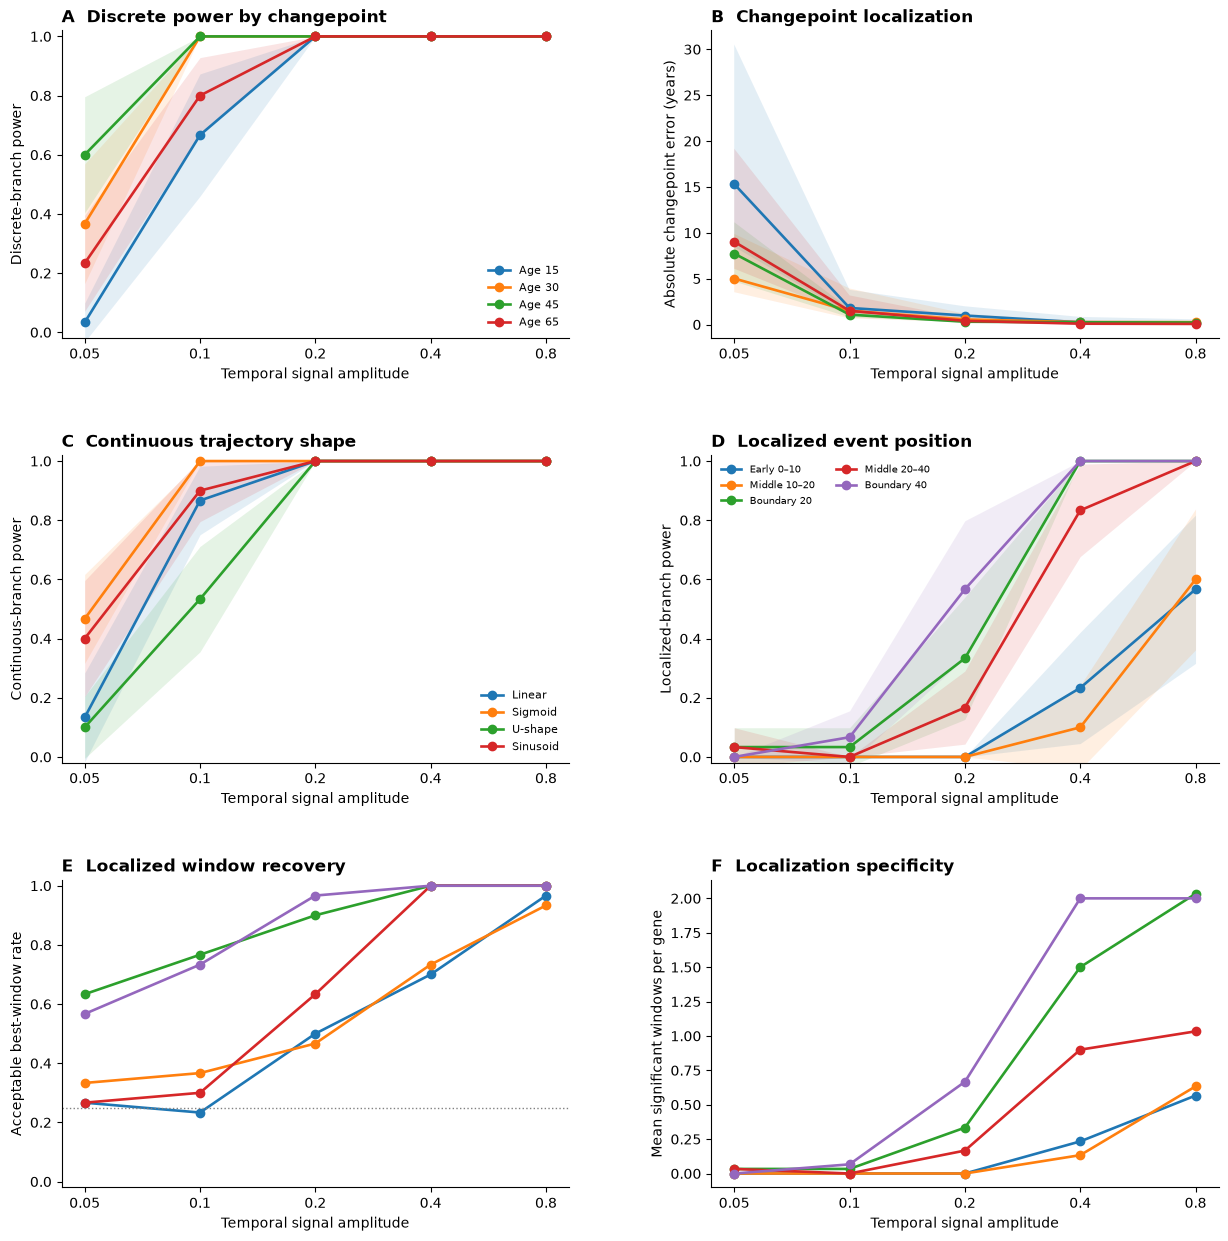

In [9]:
# ============================================================
# Final branch-specific stress figure
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(13.0, 13.0),
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.07,
    top=0.96,
    wspace=0.28,
    hspace=0.38,
)


# ============================================================
# A. Discrete power by changepoint location
# ============================================================

ax = axes[
    0,
    0,
]

sub = (
    power_summary.loc[
        power_summary[
            "branch"
        ].eq(
            "discrete"
        )
    ]
)


for change_age in (
    STEP_LOCATIONS
):

    curve = (
        sub.loc[
            pd.to_numeric(
                sub[
                    "geometry"
                ]
            ).eq(
                change_age
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    line, = ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=(
            f"Age {change_age:g}"
        ),
    )

    ax.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Discrete-branch power"
)

ax.set_title(
    "A  Discrete power by changepoint",
    loc="left",
    fontweight="bold",
)

ax.legend(
    frameon=False,
    fontsize=8,
)


# ============================================================
# B. Changepoint estimation error
# ============================================================

ax = axes[
    0,
    1,
]


for change_age in (
    STEP_LOCATIONS
):

    curve = (
        discrete_error_summary.loc[
            pd.to_numeric(
                discrete_error_summary[
                    "geometry"
                ]
            ).eq(
                change_age
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "median_error"
        ],
        marker="o",
        lw=1.9,
        label=(
            f"Age {change_age:g}"
        ),
    )

    ax.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "q25"
        ],
        curve[
            "q75"
        ],
        alpha=0.12,
    )


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Absolute changepoint error (years)"
)

ax.set_title(
    "B  Changepoint localization",
    loc="left",
    fontweight="bold",
)


# ============================================================
# C. Continuous power by trajectory shape
# ============================================================

ax = axes[
    1,
    0,
]

sub = (
    power_summary.loc[
        power_summary[
            "branch"
        ].eq(
            "continuous"
        )
    ]
)


for shape in (
    CONTINUOUS_SHAPES
):

    curve = (
        sub.loc[
            sub[
                "geometry"
            ].eq(
                shape
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    line, = ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=(
            shape.replace(
                "_",
                "-",
            ).capitalize()
        ),
    )

    ax.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Continuous-branch power"
)

ax.set_title(
    "C  Continuous trajectory shape",
    loc="left",
    fontweight="bold",
)

ax.legend(
    frameon=False,
    fontsize=8,
)


# ============================================================
# D. Localized power by event position
# ============================================================

ax = axes[
    1,
    1,
]

sub = (
    power_summary.loc[
        power_summary[
            "branch"
        ].eq(
            "localized"
        )
    ]
)


for case_label in (
    LOCALIZED_CASES
):

    curve = (
        sub.loc[
            sub[
                "geometry"
            ].eq(
                case_label
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    line, = ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=case_label.replace(
            "\n",
            " ",
        ),
    )

    ax.fill_between(
        curve[
            "signal_strength"
        ],
        curve[
            "ci_low"
        ],
        curve[
            "ci_high"
        ],
        alpha=0.12,
        color=line.get_color(),
        linewidth=0,
    )


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Localized-branch power"
)

ax.set_title(
    "D  Localized event position",
    loc="left",
    fontweight="bold",
)

ax.legend(
    frameon=False,
    fontsize=7.5,
    ncol=2,
)


# ============================================================
# E. Correct / acceptable best-window recovery
# ============================================================

ax = axes[
    2,
    0,
]


for case_label in (
    LOCALIZED_CASES
):

    curve = (
        localized_window_summary.loc[
            localized_window_summary[
                "geometry"
            ].eq(
                case_label
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=case_label.replace(
            "\n",
            " ",
        ),
    )


ax.axhline(
    0.25,
    ls=":",
    lw=1.0,
    color="0.5",
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_ylim(
    -0.02,
    1.02,
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Acceptable best-window rate"
)

ax.set_title(
    "E  Localized window recovery",
    loc="left",
    fontweight="bold",
)


# ============================================================
# F. Number of significant localized windows
# ============================================================

ax = axes[
    2,
    1,
]


for case_label in (
    LOCALIZED_CASES
):

    curve = (
        localized_multiplicity_summary.loc[
            localized_multiplicity_summary[
                "geometry"
            ].eq(
                case_label
            )
        ]
        .sort_values(
            "signal_strength"
        )
    )

    ax.plot(
        curve[
            "signal_strength"
        ],
        curve[
            "mean"
        ],
        marker="o",
        lw=1.9,
        label=case_label.replace(
            "\n",
            " ",
        ),
    )


ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    SIGNAL_STRENGTHS
)

ax.set_xticklabels(
    [
        f"{x:g}"
        for x
        in SIGNAL_STRENGTHS
    ]
)

ax.set_xlabel(
    "Temporal signal amplitude"
)

ax.set_ylabel(
    "Mean significant windows per gene"
)

ax.set_title(
    "F  Localization specificity",
    loc="left",
    fontweight="bold",
)


# ============================================================
# Cosmetics
# ============================================================

for ax in axes.ravel():

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


plt.show()